# Ireland Data Centre Demand × Price Analytics

**Project 03 — Ireland / Energy / Data**

This project combines Projects 01 and 02 to test a contested question:

> **After accounting for major energy-market drivers, does rising data-centre electricity demand add meaningful explanatory or predictive power for Irish business electricity prices?**

The goal is to test the claim, not assume it.


## Analytical guardrails

- **Correlation is not causation.**
- Trending level series can create **spurious correlation**.
- We examine levels, growth, changes, lags and regime splits.
- Gas, wholesale electricity, network costs and policy components are potential confounders.
- Prediction uses **walk-forward validation**, not random train/test splits.
- The half-year retail-price target gives only 22 observations for 2015–2025, so complexity must remain limited.
- Band IG is a public large-user benchmark, **not a data-centre tariff**.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_NAME = "Ireland Data Centre Demand x Price Analytics"

if Path("/content").exists():
    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME
    except Exception:
        PROJECT_DIR = Path.cwd()
else:
    PROJECT_DIR = Path.cwd()

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
CHARTS_DIR = PROJECT_DIR / "charts"

print("Project:", PROJECT_DIR)


Mounted at /content/drive
Project: /content/drive/MyDrive/Ireland Data Centre Demand x Price Analytics


## 1. Load the two completed-project source layers

Demand comes from Project 01 / CSO-aligned quarterly data.  
Retail electricity and gas prices come from Project 02 / SEAI biannual data.


In [2]:
dc_q = pd.read_csv(RAW_DIR / "project01_data_centre_quarterly_2015_2025.csv")
prices = pd.read_csv(RAW_DIR / "project02_business_energy_prices_biannual_2015_2025.csv")

display(dc_q.head())
display(prices.head())


,year,quarter,data_centre_gwh,all_metered_gwh,period,source_project,source_repo,official_source
0,2015,1,291,6565,2015Q1,Project 01 — Ireland Data Centre Energy Analytics,https://github.com/danielsantos2310/Ireland-Da...,https://www.cso.ie/en/releasesandpublications/...
1,2015,2,304,6086,2015Q2,Project 01 — Ireland Data Centre Energy Analytics,https://github.com/danielsantos2310/Ireland-Da...,https://www.cso.ie/en/releasesandpublications/...
2,2015,3,316,5783,2015Q3,Project 01 — Ireland Data Centre Energy Analytics,https://github.com/danielsantos2310/Ireland-Da...,https://www.cso.ie/en/releasesandpublications/...
3,2015,4,329,6165,2015Q4,Project 01 — Ireland Data Centre Energy Analytics,https://github.com/danielsantos2310/Ireland-Da...,https://www.cso.ie/en/releasesandpublications/...
4,2016,1,341,6651,2016Q1,Project 01 — Ireland Data Centre Energy Analytics,https://github.com/danielsantos2310/Ireland-Da...,https://www.cso.ie/en/releasesandpublications/...


,period,electricity_c_per_kwh,gas_c_per_kwh,year,semester,source_project,source_repo,official_source
0,2015S1,14.00,3.73,2015,1,Project 02 — Ireland Electricity Price Analytics,https://github.com/danielsantos2310/Ireland-El...,https://www.seai.ie/data-and-insights/seai-sta...
1,2015S2,13.58,3.51,2015,2,Project 02 — Ireland Electricity Price Analytics,https://github.com/danielsantos2310/Ireland-El...,https://www.seai.ie/data-and-insights/seai-sta...
2,2016S1,12.97,3.20,2016,1,Project 02 — Ireland Electricity Price Analytics,https://github.com/danielsantos2310/Ireland-El...,https://www.seai.ie/data-and-insights/seai-sta...
3,2016S2,12.53,3.30,2016,2,Project 02 — Ireland Electricity Price Analytics,https://github.com/danielsantos2310/Ireland-El...,https://www.seai.ie/data-and-insights/seai-sta...
4,2017S1,12.37,3.14,2017,1,Project 02 — Ireland Electricity Price Analytics,https://github.com/danielsantos2310/Ireland-El...,https://www.seai.ie/data-and-insights/seai-sta...


## 2. Align demand and prices at the same half-year frequency

The retail target is genuinely biannual. We therefore sum Q1+Q2 into S1 and Q3+Q4 into S2 rather than duplicating retail observations.


In [3]:
dc_q["semester"] = np.where(dc_q["quarter"] <= 2, 1, 2)

half = (
    dc_q.groupby(["year","semester"], as_index=False)
    .agg(
        data_centre_gwh=("data_centre_gwh","sum"),
        all_metered_gwh=("all_metered_gwh","sum")
    )
)

half["data_centre_share_pct"] = (
    half["data_centre_gwh"] / half["all_metered_gwh"] * 100
)
half["period"] = half["year"].astype(str) + "S" + half["semester"].astype(str)

merged = half.merge(
    prices[["period","electricity_c_per_kwh","gas_c_per_kwh"]],
    on="period",
    how="left"
)

assert len(merged) == 22
assert merged["period"].is_unique
assert merged["electricity_c_per_kwh"].notna().all()

display(merged)


,year,semester,data_centre_gwh,all_metered_gwh,data_centre_share_pct,period,electricity_c_per_kwh,gas_c_per_kwh
0,2015,1,595,12651,4.703186,2015S1,14.00,3.73
1,2015,2,645,11948,5.398393,2015S2,13.58,3.51
2,2016,1,702,13122,5.349794,2016S1,12.97,3.20
3,2016,2,781,12233,6.384370,2016S2,12.53,3.30
4,2017,1,840,13296,6.317690,2017S1,12.37,3.14
5,2017,2,922,12430,7.417538,2017S2,12.61,3.12
6,2018,1,1018,13942,7.301678,2018S1,12.75,3.26
7,2018,2,1165,12788,9.110103,2018S2,13.00,3.65
8,2019,1,1179,13477,8.748238,2019S1,12.63,3.33
9,2019,2,1310,13027,10.056037,2019S2,12.29,3.09


In [4]:
merged["dc_yoy_pct"] = merged["data_centre_gwh"].pct_change(2) * 100
merged["price_yoy_pct"] = merged["electricity_c_per_kwh"].pct_change(2) * 100
merged["gas_yoy_pct"] = merged["gas_c_per_kwh"].pct_change(2) * 100

merged["dc_index_2015S1"] = (
    merged["data_centre_gwh"] / merged.loc[0,"data_centre_gwh"] * 100
)
merged["price_index_2015S1"] = (
    merged["electricity_c_per_kwh"] / merged.loc[0,"electricity_c_per_kwh"] * 100
)
merged["gas_index_2015S1"] = (
    merged["gas_c_per_kwh"] / merged.loc[0,"gas_c_per_kwh"] * 100
)

merged.to_csv(PROCESSED_DIR / "demand_price_halfyear_2015_2025.csv", index=False)


## 3. First visual test — normalize everything to 2015 S1 = 100

This chart is descriptive only. Similar movement does not establish causation.


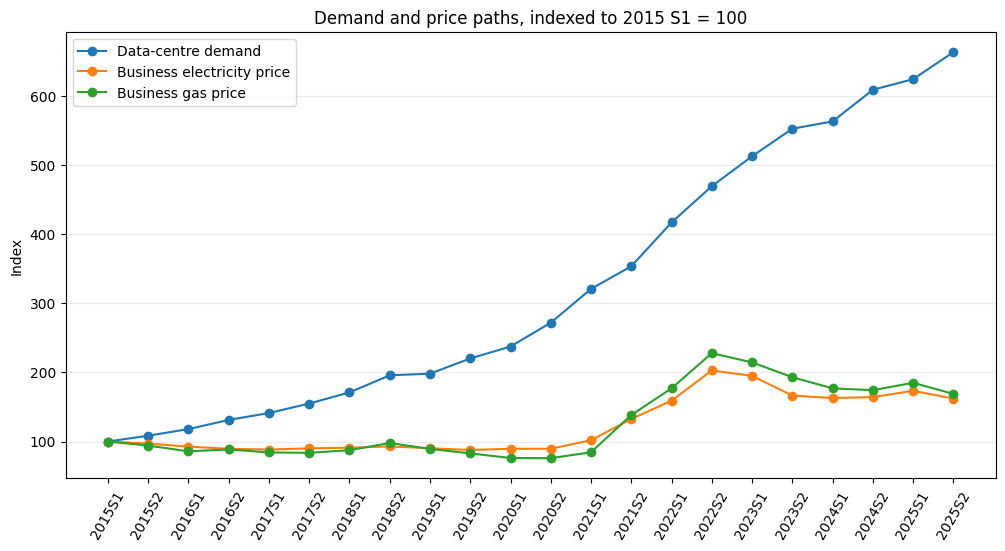

In [5]:
fig, ax = plt.subplots(figsize=(12,5.8))
ax.plot(merged["period"], merged["dc_index_2015S1"], marker="o", label="Data-centre demand")
ax.plot(merged["period"], merged["price_index_2015S1"], marker="o", label="Business electricity price")
ax.plot(merged["period"], merged["gas_index_2015S1"], marker="o", label="Business gas price")
ax.set_title("Demand and price paths, indexed to 2015 S1 = 100")
ax.set_ylabel("Index")
ax.tick_params(axis="x", rotation=60)
ax.legend()
ax.grid(axis="y", alpha=.25)
plt.show()


## 4. Level correlation vs growth correlation

A high correlation between trending level series can be misleading. We compare that with year-on-year growth relationships.


In [6]:
level_corr = merged[
    ["data_centre_gwh","data_centre_share_pct","electricity_c_per_kwh","gas_c_per_kwh"]
].corr()

growth_corr = merged[
    ["dc_yoy_pct","price_yoy_pct","gas_yoy_pct"]
].dropna().corr()

display(level_corr)
display(growth_corr)


,data_centre_gwh,data_centre_share_pct,electricity_c_per_kwh,gas_c_per_kwh
data_centre_gwh,1.000000,0.994979,0.884067,0.855985
data_centre_share_pct,0.994979,1.000000,0.882610,0.856735
electricity_c_per_kwh,0.884067,0.882610,1.000000,0.993130
gas_c_per_kwh,0.855985,0.856735,0.993130,1.000000


,dc_yoy_pct,price_yoy_pct,gas_yoy_pct
dc_yoy_pct,1.000000,0.701558,0.669231
price_yoy_pct,0.701558,1.000000,0.953488
gas_yoy_pct,0.669231,0.953488,1.000000


### Initial warning

The full 2015–2025 level relationship looks strong. But a stable causal relationship should survive reasonable regime splits and transformations.

The next checks deliberately try to break the apparent relationship.


In [7]:
pre = merged[merged["year"] <= 2020]
post = merged[merged["year"] >= 2021]

regime = pd.DataFrame({
    "window":["2015–2020","2021–2025"],
    "DC vs electricity price":[
        pre["data_centre_gwh"].corr(pre["electricity_c_per_kwh"]),
        post["data_centre_gwh"].corr(post["electricity_c_per_kwh"])
    ],
    "Gas vs electricity price":[
        pre["gas_c_per_kwh"].corr(pre["electricity_c_per_kwh"]),
        post["gas_c_per_kwh"].corr(post["electricity_c_per_kwh"])
    ]
})

display(regime)


,window,DC vs electricity price,Gas vs electricity price
0,2015–2020,-0.609205,0.763550
1,2021–2025,0.549298,0.986852


## 5. Lag screen

We test whether data-centre demand growth tends to lead, coincide with or lag retail-price growth.

This is a diagnostic correlation screen, **not a causal estimate**.


In [8]:
lag_rows = []

for shift in range(-4,5):
    temp = pd.DataFrame({
        "price_growth": merged["price_yoy_pct"],
        "dc_growth_shifted": merged["dc_yoy_pct"].shift(shift)
    }).dropna()
    lag_rows.append({
        "dc_shift_semesters": shift,
        "observations": len(temp),
        "correlation": temp["price_growth"].corr(temp["dc_growth_shifted"])
    })

lag_df = pd.DataFrame(lag_rows)
display(lag_df)
lag_df.to_csv(PROCESSED_DIR / "dc_price_growth_lag_correlations.csv", index=False)


,dc_shift_semesters,observations,correlation
0,-4,16,-0.441845
1,-3,17,-0.126030
2,-2,18,0.265958
3,-1,19,0.547014
4,0,20,0.701558
5,1,19,0.683562
6,2,18,0.431204
7,3,17,0.147684
8,4,16,-0.305013


## 6. First walk-forward predictive screen

Question:

> Does adding lagged data-centre demand improve prediction after we already know the last retail price and lagged gas price?

Models:

1. Naive — next price = last price
2. AR + gas
3. AR + gas + data-centre demand

This is only the **first screen**. Wholesale electricity and network-cost variables come next.


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

model_df = merged.copy()

for col in ["electricity_c_per_kwh","gas_c_per_kwh","data_centre_gwh"]:
    model_df[f"{col}_lag1"] = model_df[col].shift(1)

predictions = []

for i in range(len(model_df)):
    if model_df.loc[i,"year"] < 2021:
        continue

    train = model_df.iloc[:i].dropna(subset=[
        "electricity_c_per_kwh_lag1",
        "gas_c_per_kwh_lag1",
        "data_centre_gwh_lag1",
        "electricity_c_per_kwh"
    ])
    row = model_df.iloc[[i]]

    if len(train) < 6:
        continue

    actual = float(row["electricity_c_per_kwh"].iloc[0])
    naive = float(row["electricity_c_per_kwh_lag1"].iloc[0])

    ar_gas = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    ar_gas.fit(
        train[["electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1"]],
        train["electricity_c_per_kwh"]
    )

    ar_gas_dc = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    ar_gas_dc.fit(
        train[["electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1","data_centre_gwh_lag1"]],
        train["electricity_c_per_kwh"]
    )

    predictions.append({
        "period": row["period"].iloc[0],
        "actual": actual,
        "naive": naive,
        "ar_plus_gas": float(ar_gas.predict(
            row[["electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1"]]
        )[0]),
        "ar_plus_gas_plus_dc": float(ar_gas_dc.predict(
            row[["electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1","data_centre_gwh_lag1"]]
        )[0])
    })

pred = pd.DataFrame(predictions)
display(pred)

rows=[]
for model in ["naive","ar_plus_gas","ar_plus_gas_plus_dc"]:
    rows.append({
        "model":model,
        "RMSE":mean_squared_error(pred["actual"],pred[model])**0.5,
        "MAE":mean_absolute_error(pred["actual"],pred[model])
    })

evaluation = pd.DataFrame(rows).sort_values("RMSE")
display(evaluation)

pred.to_csv(PROCESSED_DIR / "initial_walkforward_predictions.csv", index=False)
evaluation.to_csv(PROCESSED_DIR / "initial_walkforward_evaluation.csv", index=False)


,period,actual,naive,ar_plus_gas,ar_plus_gas_plus_dc
0,2021S1,14.27,12.53,12.568358,12.518567
1,2021S2,18.56,14.27,14.124781,14.929991
2,2022S1,22.26,18.56,20.257298,23.534278
3,2022S2,28.40,22.26,26.846126,27.404617
4,2023S1,27.29,28.40,36.989034,35.659713
5,2023S2,23.31,27.29,28.987991,29.893158
6,2024S1,22.81,23.31,23.736751,26.317713
7,2024S2,23.00,22.81,22.689532,24.667524
8,2025S1,24.27,23.00,22.741722,24.720492
9,2025S2,22.70,24.27,24.066233,25.536787


,model,RMSE,MAE
0,naive,3.070142,2.449000
2,ar_plus_gas_plus_dc,3.944415,3.106649
1,ar_plus_gas,4.005751,2.920219


### First predictive result

The naive baseline remains difficult to beat.

At this stage, adding lagged data-centre demand does **not** outperform simply carrying the previous retail price forward.

That does **not** prove data-centre demand has no price effect. It means the simple demand feature has not yet demonstrated incremental predictive value in this small half-year sample.

The next phase adds the strongest missing confounder: **wholesale electricity prices**, followed by network-cost / policy variables.


## 7. Next stage

1. Add the validated wholesale electricity feature from Project 02.
2. Compare gas-only vs wholesale-only vs gas+wholesale models.
3. Add data-centre demand **incrementally** and measure whether out-of-sample error improves.
4. Test growth/change specifications to reduce spurious-trend risk.
5. Add network-cost and policy context where frequency alignment is defensible.
6. Only then assess what can and cannot be said about data-centre demand and electricity prices.


## 8. Add the wholesale electricity control

Wholesale electricity is a major confounder. We add the validated Project 02 wholesale feature before asking data-centre demand to explain anything incrementally.

Feature construction:

- 2019–2020: SEMOpx Day-Ahead Market index
- 2021–2025: CSO WPM37 Wholesale Price Index — Electricity

Both are normalised to a 2021≈100 scale.


,period,year,semester,wholesale_index,source_layer
0,2019S1,2019,1,39.953748,SEMOpx DAM index
1,2019S2,2019,2,34.214815,SEMOpx DAM index
2,2020S1,2020,1,22.996070,SEMOpx DAM index
3,2020S2,2020,2,32.453642,SEMOpx DAM index
4,2021S1,2021,1,59.783333,CSO WPM37 electricity index
5,2021S2,2021,2,140.216667,CSO WPM37 electricity index
6,2022S1,2022,1,149.216667,CSO WPM37 electricity index
7,2022S2,2022,2,183.716667,CSO WPM37 electricity index
8,2023S1,2023,1,100.183333,CSO WPM37 electricity index
9,2023S2,2023,2,80.166667,CSO WPM37 electricity index


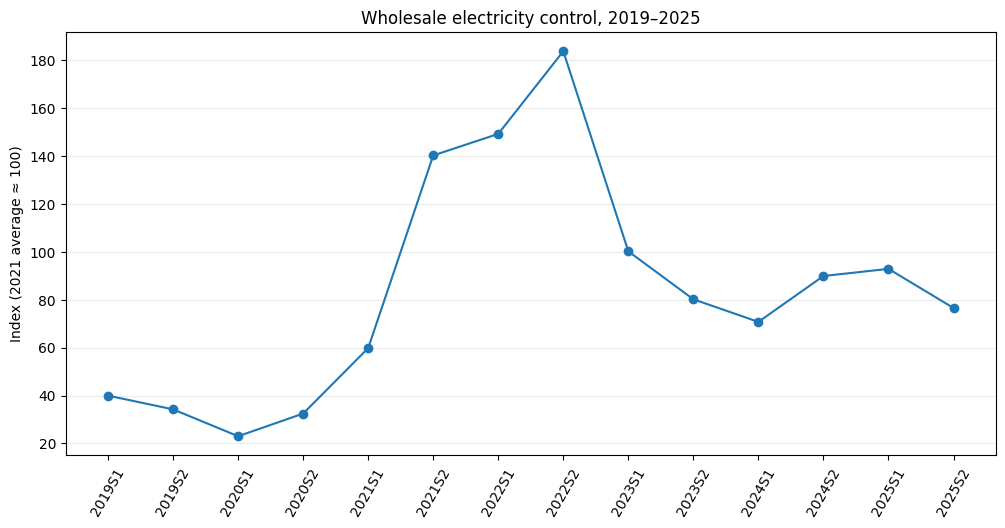

In [10]:
wholesale = pd.read_csv(PROCESSED_DIR / "wholesale_control_halfyear_2019_2025.csv")
display(wholesale)

analysis = merged.merge(
    wholesale[["period","wholesale_index"]],
    on="period",
    how="left"
)

fig, ax = plt.subplots(figsize=(12,5.5))
ax.plot(wholesale["period"], wholesale["wholesale_index"], marker="o")
ax.set_title("Wholesale electricity control, 2019–2025")
ax.set_ylabel("Index (2021 average ≈ 100)")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=.25)
plt.show()


## 9. Incremental predictive test

We now compare, on the **same walk-forward test periods**:

1. naive last price;
2. AR + gas;
3. AR + wholesale;
4. AR + gas + wholesale;
5. AR + gas + wholesale + data-centre demand.

The final comparison is the important one: **does DC demand improve the already-controlled model?**


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

for col in [
    "electricity_c_per_kwh",
    "gas_c_per_kwh",
    "data_centre_gwh",
    "wholesale_index"
]:
    analysis[f"{col}_lag1"] = analysis[col].shift(1)

specs = {
    "naive": None,
    "AR + gas": ["electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1"],
    "AR + wholesale": ["electricity_c_per_kwh_lag1","wholesale_index_lag1"],
    "AR + gas + wholesale": [
        "electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1","wholesale_index_lag1"
    ],
    "AR + gas + wholesale + DC": [
        "electricity_c_per_kwh_lag1","gas_c_per_kwh_lag1",
        "wholesale_index_lag1","data_centre_gwh_lag1"
    ]
}

rows=[]

for i in range(len(analysis)):
    if analysis.loc[i,"year"] < 2022:
        continue

    train = analysis.iloc[:i].dropna(subset=[
        "electricity_c_per_kwh",
        "electricity_c_per_kwh_lag1",
        "gas_c_per_kwh_lag1",
        "wholesale_index_lag1",
        "data_centre_gwh_lag1"
    ])
    row = analysis.iloc[[i]]

    if len(train) < 6 or pd.isna(row["wholesale_index_lag1"].iloc[0]):
        continue

    rec = {
        "period": row["period"].iloc[0],
        "actual": float(row["electricity_c_per_kwh"].iloc[0]),
        "naive": float(row["electricity_c_per_kwh_lag1"].iloc[0])
    }

    for name, features in specs.items():
        if name == "naive":
            continue
        model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        model.fit(train[features], train["electricity_c_per_kwh"])
        rec[name] = float(model.predict(row[features])[0])

    rows.append(rec)

wholesale_predictions = pd.DataFrame(rows)
display(wholesale_predictions)

evaluation_rows=[]

for name in specs:
    evaluation_rows.append({
        "model": name,
        "RMSE": mean_squared_error(
            wholesale_predictions["actual"], wholesale_predictions[name]
        ) ** 0.5,
        "MAE": mean_absolute_error(
            wholesale_predictions["actual"], wholesale_predictions[name]
        )
    })

wholesale_evaluation = (
    pd.DataFrame(evaluation_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(wholesale_evaluation)


,period,actual,naive,AR + gas,AR + wholesale,AR + gas + wholesale,AR + gas + wholesale + DC
0,2022S2,28.40,22.26,27.234991,25.714096,25.360855,26.337208
1,2023S1,27.29,28.40,35.893134,33.757897,34.349965,33.727848
2,2023S2,23.31,27.29,28.629438,23.740899,24.345972,27.396759
3,2024S1,22.81,23.31,24.076329,20.638990,21.075620,23.803624
4,2024S2,23.00,22.81,22.983762,20.393634,20.595473,22.599171
5,2025S1,24.27,23.00,22.974550,22.041016,22.056951,24.570444
6,2025S2,22.70,24.27,24.135176,23.119898,23.135958,24.976461


,model,RMSE,MAE
0,naive,2.906544,2.108571
1,AR + wholesale,3.067911,2.430137
2,AR + gas + wholesale + DC,3.135581,2.365537
3,AR + gas + wholesale,3.252037,2.560428
4,AR + gas,3.946234,2.728682


### Wholesale-control result

Wholesale information substantially improves the controlled models compared with gas-only.

Adding data-centre demand also improves the **gas + wholesale** specification in this small test.

But the decisive result remains:

> **The model with data-centre demand still does not beat the naive out-of-sample benchmark.**

With only a handful of common wholesale-era test observations, this is evidence to remain cautious—not proof of no effect.


## 10. Growth regression — does DC growth add much after gas growth?

This is an explanatory diagnostic, not a causal model.

We compare price YoY growth against:

1. gas-price YoY growth alone;
2. gas-price YoY growth + data-centre demand YoY growth.

If DC growth carries substantial independent information, the second model should improve materially.


In [12]:
import statsmodels.api as sm

growth = merged.dropna(
    subset=["price_yoy_pct","gas_yoy_pct","dc_yoy_pct"]
).copy()

gas_only = sm.OLS(
    growth["price_yoy_pct"],
    sm.add_constant(growth[["gas_yoy_pct"]])
).fit()

gas_dc = sm.OLS(
    growth["price_yoy_pct"],
    sm.add_constant(growth[["gas_yoy_pct","dc_yoy_pct"]])
).fit()

summary = pd.DataFrame([
    {
        "model":"Gas YoY only",
        "R²":gas_only.rsquared,
        "Adjusted R²":gas_only.rsquared_adj
    },
    {
        "model":"Gas YoY + DC YoY",
        "R²":gas_dc.rsquared,
        "Adjusted R²":gas_dc.rsquared_adj
    }
])

display(summary)
print("DC growth coefficient:", gas_dc.params["dc_yoy_pct"])
print("DC growth p-value:", gas_dc.pvalues["dc_yoy_pct"])


,model,R²,Adjusted R²
0,Gas YoY only,0.909140,0.904092
1,Gas YoY + DC YoY,0.916433,0.906601


DC growth coefficient: 0.3172594797658348
DC growth p-value: 0.23986266302458983


### Interpretation

Gas-price growth explains most of the observed variation in electricity-price growth in this small historical sample.

Adding data-centre demand growth produces only a modest increase in in-sample R², and the DC-growth coefficient is not statistically strong.

This does **not** establish that data centres have no system-cost impact. It says that this simple historical retail-price specification does not yet isolate a robust independent relationship.

Next: first-difference tests, shock-period sensitivity, and network-cost / policy controls.


## 11. Robustness: first differences

A level correlation can be high simply because both series trend over time.

A stronger test asks whether **changes** in data-centre demand line up with **changes** in electricity prices after controlling for changes in gas and wholesale electricity.

We use half-year first differences:

- Δ business electricity price
- Δ business gas price
- Δ wholesale electricity index
- Δ data-centre demand


In [13]:
robust = analysis.copy()

for col in [
    "electricity_c_per_kwh",
    "gas_c_per_kwh",
    "data_centre_gwh",
    "data_centre_share_pct",
    "wholesale_index"
]:
    robust[f"d_{col}"] = robust[col].diff()

diff_corr = robust[[
    "d_electricity_c_per_kwh",
    "d_gas_c_per_kwh",
    "d_data_centre_gwh",
    "d_data_centre_share_pct",
    "d_wholesale_index"
]].dropna().corr()

display(diff_corr)


,d_electricity_c_per_kwh,d_gas_c_per_kwh,d_data_centre_gwh,d_data_centre_share_pct,d_wholesale_index
d_electricity_c_per_kwh,1.000000,0.949189,0.341456,0.123258,0.679907
d_gas_c_per_kwh,0.949189,1.000000,0.410306,0.258587,0.737475
d_data_centre_gwh,0.341456,0.410306,1.000000,0.607017,0.115151
d_data_centre_share_pct,0.123258,0.258587,0.607017,1.000000,0.346154
d_wholesale_index,0.679907,0.737475,0.115151,0.346154,1.000000


In [14]:
import statsmodels.api as sm

diff = robust.dropna(subset=[
    "d_electricity_c_per_kwh",
    "d_gas_c_per_kwh",
    "d_data_centre_gwh",
    "d_wholesale_index"
]).copy()

diff_base = sm.OLS(
    diff["d_electricity_c_per_kwh"],
    sm.add_constant(diff[[
        "d_gas_c_per_kwh",
        "d_wholesale_index"
    ]])
).fit(cov_type="HAC", cov_kwds={"maxlags":1})

diff_dc = sm.OLS(
    diff["d_electricity_c_per_kwh"],
    sm.add_constant(diff[[
        "d_gas_c_per_kwh",
        "d_wholesale_index",
        "d_data_centre_gwh"
    ]])
).fit(cov_type="HAC", cov_kwds={"maxlags":1})

difference_summary = pd.DataFrame([
    {
        "model":"ΔPrice ~ ΔGas + ΔWholesale",
        "R²":diff_base.rsquared,
        "Adjusted R²":diff_base.rsquared_adj,
        "AIC":diff_base.aic
    },
    {
        "model":"ΔPrice ~ ΔGas + ΔWholesale + ΔDC",
        "R²":diff_dc.rsquared,
        "Adjusted R²":diff_dc.rsquared_adj,
        "AIC":diff_dc.aic
    }
])

display(difference_summary)
print("ΔDC coefficient:", diff_dc.params["d_data_centre_gwh"])
print("ΔDC HAC p-value:", diff_dc.pvalues["d_data_centre_gwh"])


,model,R²,Adjusted R²,AIC
0,ΔPrice ~ ΔGas + ΔWholesale,0.901845,0.882214,37.373834
1,ΔPrice ~ ΔGas + ΔWholesale + ΔDC,0.906039,0.874719,38.806105


ΔDC coefficient: -0.0021355826010962795
ΔDC HAC p-value: 0.49008668742456907


### First-difference result

The controlled first-difference model explains most of the observed short-run price movement using gas and wholesale changes.

Adding the change in data-centre demand provides only a small improvement in raw R², worsens adjusted R² / AIC, and the ΔDC coefficient is not statistically strong.

This is stronger evidence against interpreting the large raw level correlation as an independent short-run price effect.


## 12. Crisis-window sensitivity

The 2021–2023 energy crisis can dominate correlations.

We therefore compare:

- pre-crisis;
- crisis / normalisation period;
- post-crisis;
- the full sample with the crisis window removed.

For this diagnostic, **2021 S2–2023 S2** is treated as the crisis / normalisation window.


In [15]:
crisis_periods = {
    "2021S2","2022S1","2022S2","2023S1","2023S2"
}

robust["crisis_window"] = robust["period"].isin(crisis_periods)

def safe_corr(df, a, b):
    part = df[[a,b]].dropna()
    return part[a].corr(part[b]) if len(part) >= 3 else np.nan

windows = {
    "Full 2015–2025": robust,
    "Pre-crisis": robust[robust["period"] <= "2021S1"],
    "Crisis / normalisation": robust[robust["crisis_window"]],
    "Post-crisis": robust[robust["period"] >= "2024S1"],
    "Excluding crisis": robust[~robust["crisis_window"]],
}

rows = []

for name, frame in windows.items():
    rows.append({
        "window":name,
        "DC level vs price":safe_corr(
            frame,"data_centre_gwh","electricity_c_per_kwh"
        ),
        "DC YoY vs price YoY":safe_corr(
            frame,"dc_yoy_pct","price_yoy_pct"
        ),
        "Gas YoY vs price YoY":safe_corr(
            frame,"gas_yoy_pct","price_yoy_pct"
        )
    })

regime_sensitivity = pd.DataFrame(rows)
display(regime_sensitivity)


,window,DC level vs price,DC YoY vs price YoY,Gas YoY vs price YoY
0,Full 2015–2025,0.884067,0.701558,0.953488
1,Pre-crisis,0.029986,0.805696,0.665951
2,Crisis / normalisation,0.645010,0.966958,0.937711
3,Post-crisis,0.080406,0.385922,0.934707
4,Excluding crisis,0.944559,0.567632,0.728753


### Regime result

The apparent relationship between data-centre demand and retail prices changes materially depending on the selected window.

A relationship that changes sign or strength across regimes should not be presented as a stable causal coefficient.


## 13. Trend-controlled wholesale-era model

The next robustness check controls explicitly for:

- time trend;
- business gas price;
- wholesale electricity;
- then adds data-centre demand.

This is still a small-sample explanatory regression, not a causal design.


In [16]:
trend = robust.dropna(subset=["wholesale_index"]).copy().reset_index(drop=True)
trend["time"] = np.arange(len(trend))

trend_base = sm.OLS(
    trend["electricity_c_per_kwh"],
    sm.add_constant(trend[[
        "time",
        "gas_c_per_kwh",
        "wholesale_index"
    ]])
).fit(cov_type="HAC", cov_kwds={"maxlags":1})

trend_dc = sm.OLS(
    trend["electricity_c_per_kwh"],
    sm.add_constant(trend[[
        "time",
        "gas_c_per_kwh",
        "wholesale_index",
        "data_centre_gwh"
    ]])
).fit(cov_type="HAC", cov_kwds={"maxlags":1})

trend_summary = pd.DataFrame([
    {
        "model":"Time + gas + wholesale",
        "R²":trend_base.rsquared,
        "Adjusted R²":trend_base.rsquared_adj,
        "AIC":trend_base.aic
    },
    {
        "model":"Time + gas + wholesale + DC",
        "R²":trend_dc.rsquared,
        "Adjusted R²":trend_dc.rsquared_adj,
        "AIC":trend_dc.aic
    }
])

display(trend_summary)
print("DC coefficient:", trend_dc.params["data_centre_gwh"])
print("DC HAC p-value:", trend_dc.pvalues["data_centre_gwh"])


,model,R²,Adjusted R²,AIC
0,Time + gas + wholesale,0.990445,0.987579,30.943586
1,Time + gas + wholesale + DC,0.991579,0.987836,31.175518


DC coefficient: -0.003941615689479247
DC HAC p-value: 0.21095990896312633


### Trend-controlled result

Once time, gas and wholesale electricity are already in the model, adding DC demand changes fit only marginally.

The DC coefficient is not statistically strong and should not be interpreted causally.


## 14. DC lag sensitivity

A possible argument is that data-centre demand affects retail prices only after a delay.

We therefore test DC-demand lags from:

- 1 semester = ~6 months
- 2 semesters = ~12 months
- 3 semesters = ~18 months
- 4 semesters = ~24 months

All models use the **same common out-of-sample window** so the comparison remains fair.


,model,rmse,mae,test_period,test_observations
0,AR+gas+wholesale,1.729203,1.564777,2023S2–2025S2,5
1,naive,2.010189,1.502000,2023S2–2025S2,5
2,+ DC lag4,2.120443,1.625417,2023S2–2025S2,5
3,+ DC lag1,2.150446,1.611623,2023S2–2025S2,5
4,+ DC lag2,2.281157,1.590981,2023S2–2025S2,5
5,+ DC lag3,2.715926,1.863322,2023S2–2025S2,5


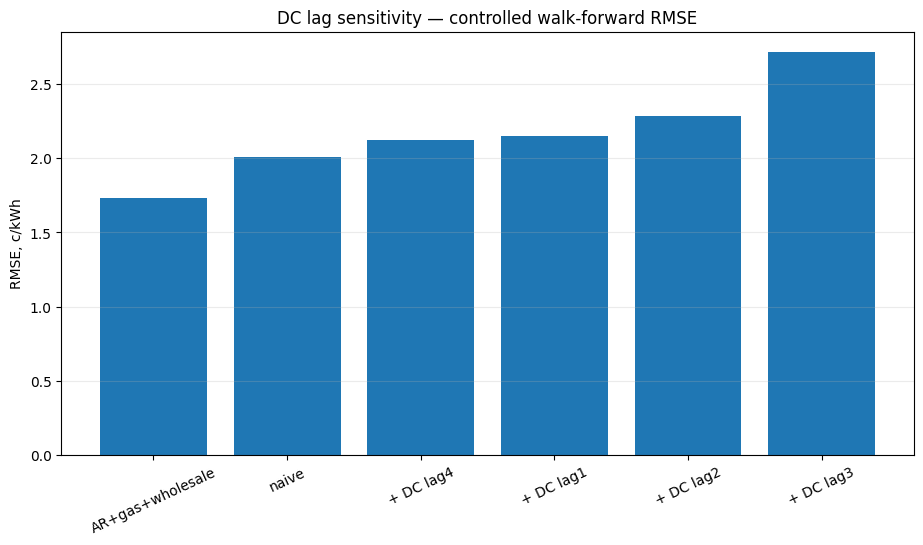

In [17]:
lag_evaluation = pd.read_csv(
    PROCESSED_DIR / "dc_lag_walkforward_evaluation.csv"
)

display(lag_evaluation)

fig, ax = plt.subplots(figsize=(11,5.5))
ax.bar(lag_evaluation["model"], lag_evaluation["rmse"])
ax.set_title("DC lag sensitivity — controlled walk-forward RMSE")
ax.set_ylabel("RMSE, c/kWh")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=.25)
plt.show()


### Lag result

None of the tested 6–24 month DC-demand lags improves the controlled forecast enough to beat the strongest comparison models.

The common test set is very small, so this is a cautionary result—not a definitive absence-of-effect result.


## 15. Network-cost mechanism — separate from wholesale prices

There is another possible channel:

> Rising electricity demand may require more network investment, and network investment is recovered through tariffs.

This is conceptually different from a direct wholesale-price effect.

To examine the mechanism without inventing a half-year series, we use Eurostat's **annual Band IG (>150,000 MWh/year) component data**.

Band IG remains a public large-user benchmark, not a data-centre tariff.


,year,data_centre_gwh,data_centre_share_pct,energy_supply_c_per_kwh,network_c_per_kwh
0,2018,2183,8.166854,7.05,0.85
1,2019,2489,9.391035,6.95,1.08
2,2020,3031,11.202691,6.29,1.11
3,2021,4013,14.077738,13.43,0.51
4,2022,5274,17.683152,24.49,1.17
5,2023,6339,20.728557,19.12,0.72
6,2024,6974,21.859328,16.04,0.88
7,2025,7662,23.227332,14.35,3.04


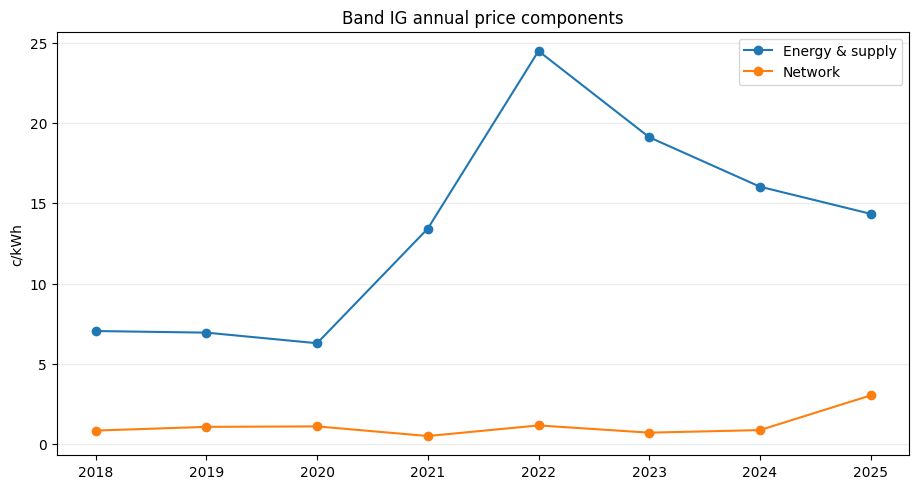

In [18]:
ig_components = pd.read_csv(
    RAW_DIR / "eurostat_band_ig_components_2018_2025.csv"
)

network_annual = pd.read_csv(
    PROCESSED_DIR / "annual_dc_demand_vs_band_ig_components_2018_2025.csv"
)

display(
    network_annual[[
        "year",
        "data_centre_gwh",
        "data_centre_share_pct",
        "energy_supply_c_per_kwh",
        "network_c_per_kwh"
    ]]
)

fig, ax = plt.subplots(figsize=(11,5.5))
ax.plot(
    network_annual["year"],
    network_annual["energy_supply_c_per_kwh"],
    marker="o",
    label="Energy & supply"
)
ax.plot(
    network_annual["year"],
    network_annual["network_c_per_kwh"],
    marker="o",
    label="Network"
)
ax.set_title("Band IG annual price components")
ax.set_ylabel("c/kWh")
ax.legend()
ax.grid(axis="y", alpha=.25)
plt.show()


### 2024 → 2025 component divergence

For Band IG:

- the **network component rose sharply**;
- the **energy & supply component fell**.

This shows why "electricity price" should not be treated as one undifferentiated mechanism.

A retail bill can face increasing infrastructure/network cost pressure while energy-market costs are falling.


In [19]:
display(
    network_annual.loc[
        network_annual["year"].isin([2024,2025]),
        [
            "year",
            "data_centre_gwh",
            "energy_supply_c_per_kwh",
            "network_c_per_kwh",
            "network_share_of_energy_plus_network_pct"
        ]
    ]
)

print(
    "Correlation — DC demand vs IG network component:",
    network_annual["data_centre_gwh"].corr(
        network_annual["network_c_per_kwh"]
    )
)


,year,data_centre_gwh,energy_supply_c_per_kwh,network_c_per_kwh,network_share_of_energy_plus_network_pct
6,2024,6974,16.04,0.88,5.200946
7,2025,7662,14.35,3.04,17.481311


Correlation — DC demand vs IG network component: 0.4884574333374834


> **Do not interpret the annual network-component correlation causally.**
>
> There are only eight annual observations, and Ireland's network investment supports many drivers simultaneously: renewable generation, interconnection, electrification, security of supply, housing, business growth and general demand growth.

Official network context:
- CRU revenues and tariffs: https://www.cru.ie/en-ie/regulations-policy/energy/revenues-and-tariffs/
- PR6 investment: https://www.cru.ie/en-ie/about-us/news/cru-approves-record-investment-in-irelands-electricity-grid-and-network/
- 2026/27 network charges: https://www.cru.ie/en-ie/about-us/news/cru-approves-202627-electricity-network-charges-and-reduced-pso-levy/


## 16. Stage 3 interim conclusion

The evidence so far supports a more nuanced answer than the headline question suggests.

### What the data support

- Data-centre demand rose extremely quickly.
- The raw level correlation with electricity prices is high over 2015–2025.
- That correlation is unstable across sub-periods.
- Gas and wholesale electricity explain the crisis-era retail-price movement much more directly.
- DC demand has not produced robust incremental predictive value in walk-forward tests.
- First-difference and trend-controlled models do not isolate a statistically strong DC term.
- Network costs are a plausible **indirect system-cost mechanism**, but public component data do not identify what share of network investment is attributable specifically to data centres.

### Current working interpretation

> The evidence does **not** support the simple claim that rising data-centre electricity use directly caused the observed Irish business-price surge.

A more defensible hypothesis is that data-centre growth may contribute to **long-run infrastructure and capacity requirements**, while the 2021–2023 retail-price shock was dominated by broader energy-market factors such as gas and wholesale electricity.

The next stage will quantify this distinction more explicitly and prepare the final conclusion / interactive story.


## 17. Stage 4 — Final synthesis

We now combine the historical, predictive and mechanism tests into one evidence hierarchy.

The question is no longer simply:

> Do data centres and electricity prices move together?

Instead:

> **After controlling for the strongest observed market drivers, what can we actually say about direct price effects, indirect network effects, and future cost exposure?**


In [20]:
evidence = pd.read_csv(
    PROCESSED_DIR / "final_evidence_hierarchy.csv"
)

display(evidence)


,question,finding,evidence_strength,interpretation
0,Did data-centre electricity demand rise materi...,Yes — from about 5% of metered demand in 2015 ...,High,"Observed fact, not causal inference."
1,Do DC demand and business electricity-price le...,"Yes, strongly over the full 2015–2025 window.",High association / low causal value,Trending levels and regime instability make th...
2,Did gas and wholesale electricity explain the ...,"Yes, much more directly than DC demand in grow...",Strong,Short-run retail-price shock is primarily ener...
3,Does adding DC demand improve out-of-sample pr...,Not robustly. Tested DC features/lags do not c...,Weak / mixed,No robust incremental predictive evidence from...
4,Could DC growth contribute indirectly through ...,"Plausible, but public data do not isolate a DC...",Moderate mechanism / weak attribution,Network-cost channel should be described as pl...
5,Can Project 03 estimate the actual electricity...,No.,Not identifiable from public data,Band IG is a benchmark only; private contracts...


### Evidence hierarchy

The project separates **association**, **prediction**, **mechanism** and **identification**.

This matters because a strong visual correlation can coexist with weak causal evidence.


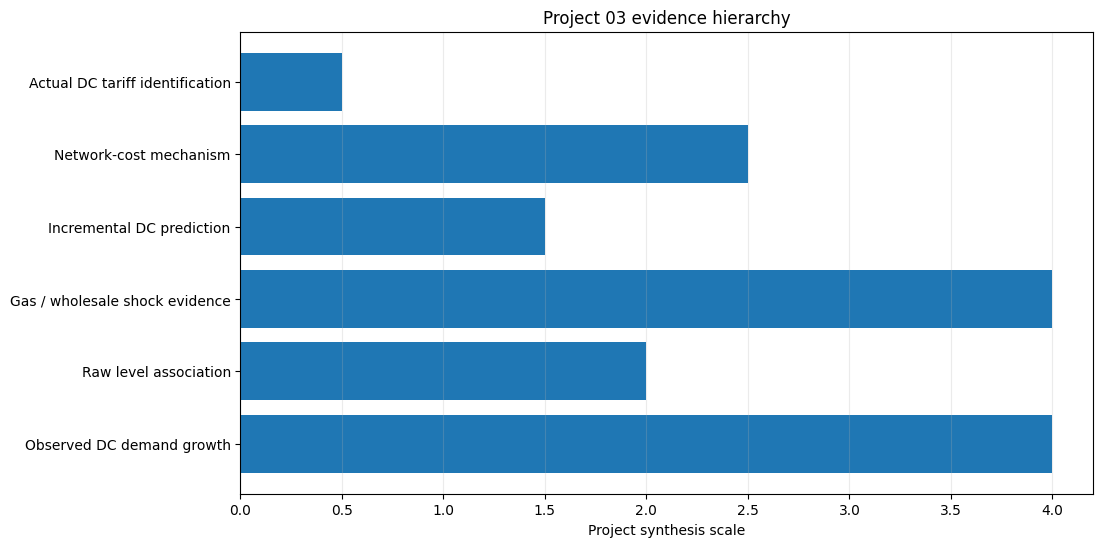

In [21]:
fig, ax = plt.subplots(figsize=(11,6))

strength_map = {
    "High":4.0,
    "High association / low causal value":2.0,
    "Strong":4.0,
    "Weak / mixed":1.5,
    "Moderate mechanism / weak attribution":2.5,
    "Not identifiable from public data":0.5
}

plot_evidence = evidence.copy()
plot_evidence["score"] = plot_evidence["evidence_strength"].map(strength_map)

labels = [
    "Observed DC demand growth",
    "Raw level association",
    "Gas / wholesale shock evidence",
    "Incremental DC prediction",
    "Network-cost mechanism",
    "Actual DC tariff identification"
]

ax.barh(labels, plot_evidence["score"])
ax.set_xlim(0,4.2)
ax.set_xlabel("Project synthesis scale")
ax.set_title("Project 03 evidence hierarchy")
ax.grid(axis="x", alpha=.25)
plt.show()


## 18. Direct vs indirect mechanism

Project 03 distinguishes two very different channels.

### Direct short-run energy-price channel

**Gas / wholesale electricity → supplier energy cost → business retail price**

This channel is strongly visible in the 2021–2023 shock.

### Indirect long-run infrastructure channel

**Electricity-demand growth → grid / network / capacity investment → network tariffs**

This mechanism is plausible and supported by the scale of current network investment, but the available public data do not isolate how much of that investment is specifically attributable to data centres.


In [22]:
mechanisms = pd.read_csv(
    PROCESSED_DIR / "final_mechanism_matrix.csv"
)

display(mechanisms)


,mechanism,pathway,evidence,limitation
0,Direct short-run energy-price channel,Gas / wholesale market → supplier energy cost ...,Strong evidence for 2021–2023 shock,DC demand is not the dominant identified driver
1,Indirect network/capacity channel,Demand growth → grid/capacity investment → net...,Plausible and policy-supported,DC-specific allocation cannot be isolated
2,Long-run system adequacy channel,Large-load growth → generation / flexibility /...,Plausible,Requires system-model or counterfactual alloca...
3,Private procurement channel,PPAs / hedging / negotiated contracts,Material but unobserved,Public Band IG data cannot recover actual DC t...


## 19. Forward exposure — not a tariff forecast

Projects 01 and 02 can be combined carefully.

Project 01 provides a data-centre electricity-demand forecast.

Project 02 provides **Band IG large-user benchmark price scenarios**.

Multiplying them answers a useful sensitivity question:

> If projected data-centre electricity use were valued at the public Band IG benchmark scenario price, what scale of annual electricity expenditure would that imply?

This is **not**:

- an actual data-centre tariff forecast;
- an estimate of private PPAs;
- a causal allocation of system costs;
- evidence that data centres caused the scenario price.


,scenario,data_centre_gwh,band_ig_real_c_per_kwh,benchmark_expenditure_billion_eur
0,Low-cost transition,14305.81231,14.055434,2.010744
1,Central,14305.81231,16.246478,2.324191
2,High-cost / constrained,14305.81231,20.262242,2.898678


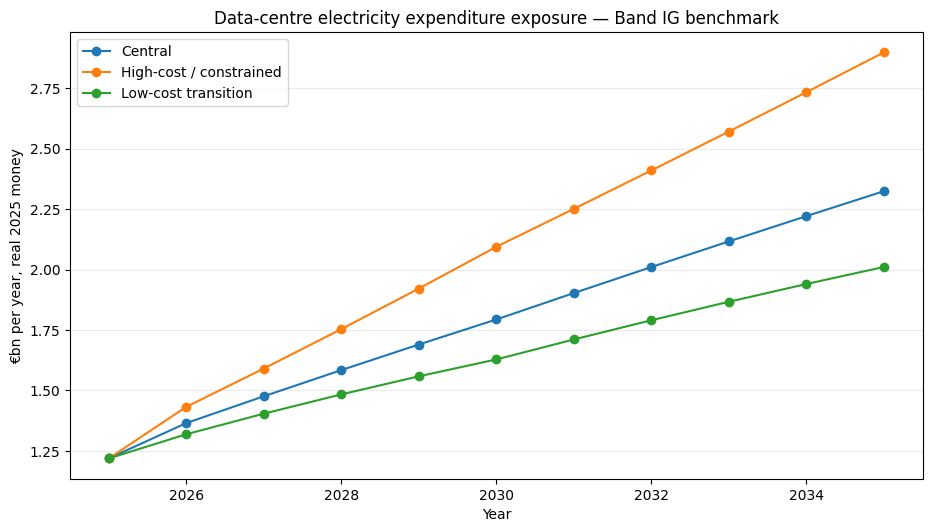

In [23]:
exposure = pd.read_csv(
    PROCESSED_DIR / "dc_cost_exposure_band_ig_scenarios_2025_2035.csv"
)

summary_2035 = pd.read_csv(
    PROCESSED_DIR / "dc_cost_exposure_2035_summary.csv"
)

display(summary_2035)

fig, ax = plt.subplots(figsize=(11,5.8))

for scenario, frame in exposure.groupby("scenario"):
    ax.plot(
        frame["year"],
        frame["benchmark_expenditure_billion_eur"],
        marker="o",
        label=scenario
    )

ax.set_title(
    "Data-centre electricity expenditure exposure — Band IG benchmark"
)
ax.set_xlabel("Year")
ax.set_ylabel("€bn per year, real 2025 money")
ax.grid(axis="y", alpha=.25)
ax.legend()
plt.show()


### 2035 exposure range

Project 01 forecasts approximately **14.31 TWh** of annual data-centre electricity consumption in 2035.

Using the Project 02 Band IG benchmark scenarios in real 2025 money:

- **Low-cost transition:** approximately **€2.01bn/year**
- **Central:** approximately **€2.32bn/year**
- **High-cost / constrained:** approximately **€2.90bn/year**

Again: these are **benchmark expenditure sensitivities**, not observed or predicted private procurement costs.


## 20. Final answer to the headline question

> **Are Ireland's data centres driving electricity prices?**

### Evidence-based answer

**Not in the simple direct sense implied by the headline.**

Data-centre electricity consumption has risen dramatically and the raw 2015–2025 level correlation with business electricity prices is high.

But that relationship weakens or changes when we:

- compare year-on-year growth;
- use first differences;
- split the sample into regimes;
- test 6–24 month lags;
- control for gas and wholesale electricity;
- compare out-of-sample forecast performance.

Gas and wholesale electricity explain the 2021–2023 retail-price shock much more directly.

Across the tested models, data-centre demand does **not** provide robust incremental predictive value.

### What remains plausible

Data-centre growth may contribute to long-run infrastructure and capacity requirements.

That could create an **indirect system-cost effect** through network investment and tariffs.

But the public data used here do not provide a defensible method for assigning a specific share of those costs to data centres alone.

### Final interpretation

> **The evidence does not support the claim that rising data-centre electricity use directly caused Ireland's observed business-electricity price surge.**
>
> **A more defensible interpretation is that the short-run price shock was dominated by gas and wholesale electricity, while data-centre growth may contribute to longer-run infrastructure requirements whose cost attribution remains unresolved.**


## 21. What this project cannot identify

Project 03 deliberately stops where the public evidence stops.

It cannot identify:

- actual private data-centre electricity tariffs;
- individual PPAs or hedging arrangements;
- a data-centre-specific share of PR6 network investment;
- a causal counterfactual for Ireland without data-centre growth;
- exact marginal network cost caused by one customer class.

A true causal estimate would require richer system-level or customer-level data and a credible counterfactual design.

That limitation is part of the result, not something to hide.


## 22. Publication-ready takeaway

**Ireland / Energy / Data — Project 03**

Data centres now account for a major share of Irish electricity demand.

But a high demand–price correlation is not enough to prove that data centres drove the electricity-price surge.

After testing growth rates, first differences, lag structures, crisis-period sensitivity, gas, wholesale electricity and out-of-sample prediction, the direct relationship is not robust.

The strongest evidence points to:

1. **gas and wholesale electricity** as the main drivers of the 2021–2023 price shock;
2. **network and capacity investment** as a plausible longer-run indirect cost channel;
3. **insufficient public evidence** to allocate those network costs specifically to data centres.

That distinction is the central finding of Project 03.
